In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder
from sklearn.compose import make_column_transformer, make_column_selector
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import OrdinalEncoder
from sklearn import set_config
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.neighbors import KNeighborsRegressor
from sklearn.datasets import make_regression
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import r2_score
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_regression, RFECV, SelectFromModel
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

In [2]:
vinhos_branco = pd.read_excel('Qualidade_Vinho.xlsx',sheet_name='Qualidade_Vinho_Branco')
vinhos_tinto = pd.read_excel('Qualidade_Vinho.xlsx',sheet_name='Qualidade_Vinho_Tinto')

vinhos_branco['tipo'] = 'branco'
vinhos_tinto['tipo'] = 'tinto'

vinhos = pd.concat([vinhos_branco,vinhos_tinto], ignore_index=True)

print(vinhos.head(5))
print(vinhos.tail(5))

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.0              0.27         0.36            20.7      0.045   
1            6.3              0.30         0.34             1.6      0.049   
2            8.1              0.28         0.40             6.9      0.050   
3            7.2              0.23         0.32             8.5      0.058   
4            7.2              0.23         0.32             8.5      0.058   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 45.0                 170.0   1.0010  3.00       0.45   
1                 14.0                 132.0   0.9940  3.30       0.49   
2                 30.0                  97.0   0.9951  3.26       0.44   
3                 47.0                 186.0   0.9956  3.19       0.40   
4                 47.0                 186.0   0.9956  3.19       0.40   

   alcohol  quality    tipo  
0      8.8      6.0  branco  
1      9.5      6.0  branc

In [3]:
vinhos.info()

<class 'pandas.DataFrame'>
RangeIndex: 6586 entries, 0 to 6585
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6580 non-null   float64
 1   volatile acidity      6571 non-null   float64
 2   citric acid           6552 non-null   float64
 3   residual sugar        6554 non-null   float64
 4   chlorides             6546 non-null   float64
 5   free sulfur dioxide   6547 non-null   float64
 6   total sulfur dioxide  6546 non-null   float64
 7   density               6550 non-null   float64
 8   pH                    6543 non-null   float64
 9   sulphates             6538 non-null   float64
 10  alcohol               6549 non-null   float64
 11  quality               6577 non-null   float64
 12  tipo                  6586 non-null   str    
dtypes: float64(12), str(1)
memory usage: 669.0 KB


In [5]:
vinhos.duplicated().sum()

np.int64(1241)

In [7]:
vinhos_desdup = vinhos.drop_duplicates()
vinhos_desdup.info()

<class 'pandas.DataFrame'>
Index: 5345 entries, 0 to 6571
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         5340 non-null   float64
 1   volatile acidity      5332 non-null   float64
 2   citric acid           5330 non-null   float64
 3   residual sugar        5332 non-null   float64
 4   chlorides             5330 non-null   float64
 5   free sulfur dioxide   5329 non-null   float64
 6   total sulfur dioxide  5329 non-null   float64
 7   density               5331 non-null   float64
 8   pH                    5326 non-null   float64
 9   sulphates             5323 non-null   float64
 10  alcohol               5327 non-null   float64
 11  quality               5342 non-null   float64
 12  tipo                  5345 non-null   str    
dtypes: float64(12), str(1)
memory usage: 584.6 KB


In [9]:
vinhos_desdup.isna().sum()

fixed acidity            5
volatile acidity        13
citric acid             15
residual sugar          13
chlorides               15
free sulfur dioxide     16
total sulfur dioxide    16
density                 14
pH                      19
sulphates               22
alcohol                 18
quality                  3
tipo                     0
dtype: int64

In [11]:
vinhos_sem_na = vinhos_desdup.dropna()
vinhos_sem_na.info()

<class 'pandas.DataFrame'>
Index: 5320 entries, 0 to 6571
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         5320 non-null   float64
 1   volatile acidity      5320 non-null   float64
 2   citric acid           5320 non-null   float64
 3   residual sugar        5320 non-null   float64
 4   chlorides             5320 non-null   float64
 5   free sulfur dioxide   5320 non-null   float64
 6   total sulfur dioxide  5320 non-null   float64
 7   density               5320 non-null   float64
 8   pH                    5320 non-null   float64
 9   sulphates             5320 non-null   float64
 10  alcohol               5320 non-null   float64
 11  quality               5320 non-null   float64
 12  tipo                  5320 non-null   str    
dtypes: float64(12), str(1)
memory usage: 581.9 KB


In [12]:
vinhos_sem_na.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,5320.000000,5320.000000,5320.000000,5320.000000,5320.000000,5320.000000,5320.000000,5320.000000,5320.000000,5320.000000,5320.000000,5320.000000
mean,7.215179,0.344130,0.318494,5.048477,0.056690,30.036654,114.109023,0.994535,3.224664,0.533357,10.549241,5.795677
std,1.319671,0.168248,0.147157,4.500180,0.036863,17.805045,56.774223,0.002966,0.160379,0.149743,1.185933,0.879772
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.400000,0.230000,0.240000,1.800000,0.038000,16.000000,74.000000,0.992200,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.300000,0.310000,2.700000,0.047000,28.000000,116.000000,0.994650,3.210000,0.510000,10.400000,6.000000
75%,7.700000,0.410000,0.400000,7.500000,0.066000,41.000000,153.250000,0.996770,3.330000,0.600000,11.400000,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000


In [14]:
vinhos_sem_na.describe(include='O')

,tipo
count,5320
unique,2
top,branco
freq,3961


In [13]:
x = vinhos_sem_na
y = x.pop("quality")

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

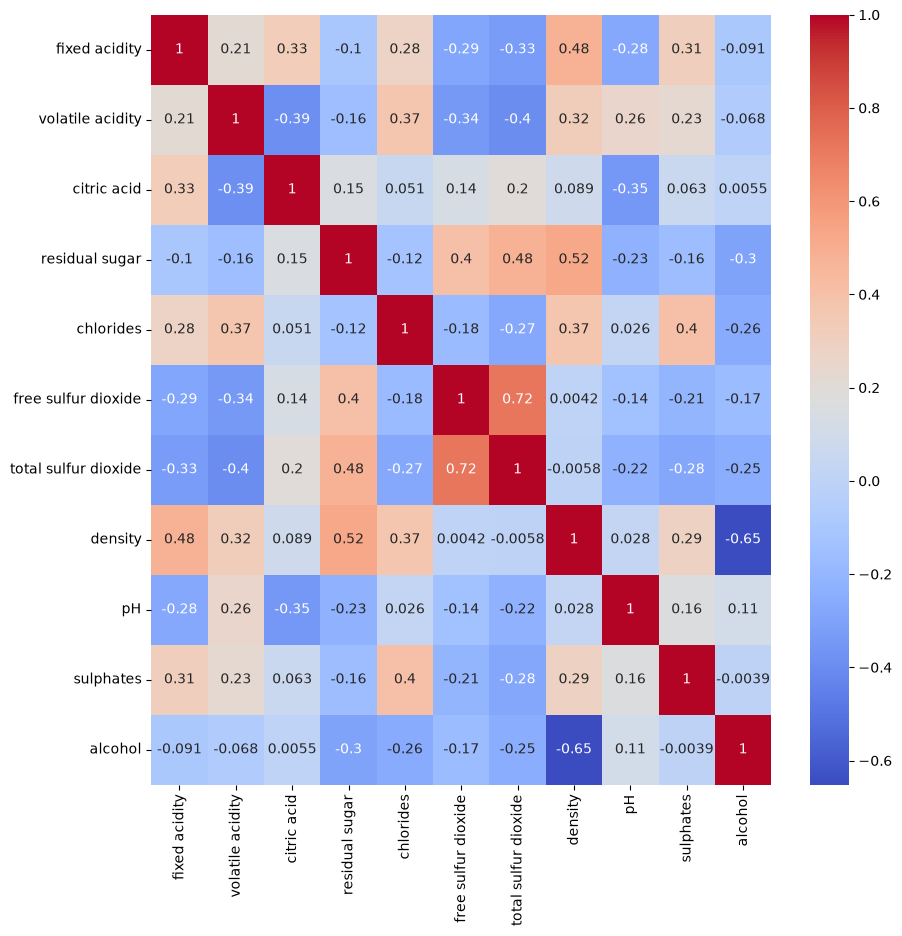

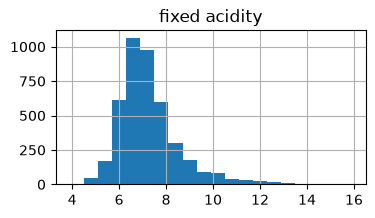

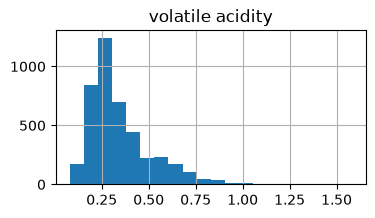

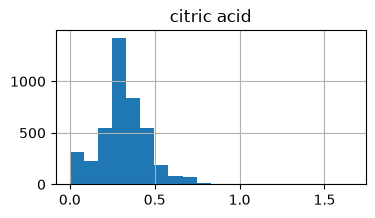

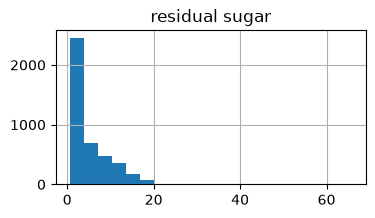

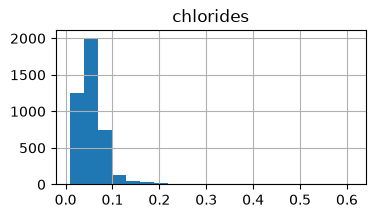

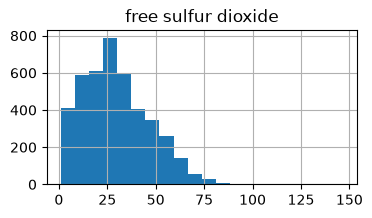

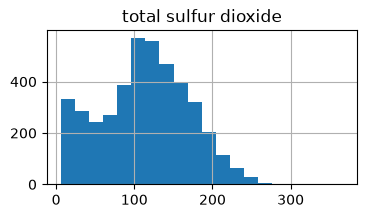

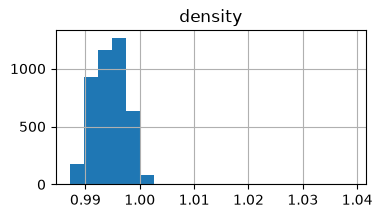

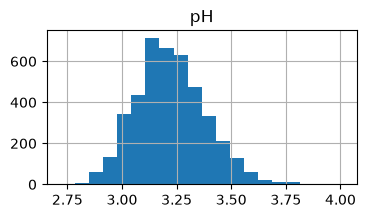

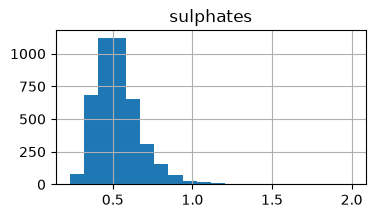

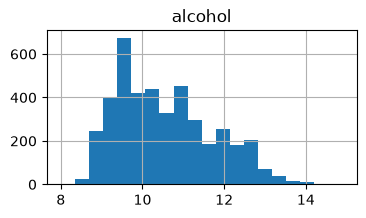

In [24]:
# Análise de Correlação para variáveis numéricas
# Calcula a correlação entre as variáveis numéricas.
correlation_matrix = x_train.select_dtypes(
   include=['int64', 'float64']
).corr()
plt.figure(figsize=(10, 10))
# Exibe a matriz de correlação em um mapa de calor.
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.show()


# Criação de histogramas para todas as variáveis numéricas
# Seleciona apenas as colunas numéricas.
numerical_columns = x_train.select_dtypes(
    include=['int64', 'float64']
).columns

# Cria um histograma para cada variável numérica.
for column in numerical_columns:
    plt.figure(figsize=(4, 2))
    x_train[column].hist(bins=20)
    plt.title(column)
    plt.show()

In [15]:
CATEGORICOS = ['tipo']
NUMERICAS_STANDARD = ["fixed acidity",
                      "volatile acidity",
                      "citric acid",
                      "density",
                      "pH",
                      "alcohol"]

NUMERICAS_ROBUSTAS = ["residual sugar",
                      "chlorides",
                      "free sulfur dioxide",
                      "total sulfur dioxide",
                      "sulphates"]

numeric_standard_pipe = make_pipeline(StandardScaler())

numeric_robust_pipe = make_pipeline(RobustScaler())

categoric_pipe = make_pipeline(OneHotEncoder(sparse_output=False, handle_unknown="ignore"))

preprocessor = ColumnTransformer(
    transformers=[
        ("num_stand_pipe",numeric_standard_pipe,NUMERICAS_STANDARD),
        ("num_robust_pipe",numeric_robust_pipe,NUMERICAS_ROBUSTAS),
        ("cat_pipe",categoric_pipe,CATEGORICOS)
    ]
)

In [22]:
pipeline_RandomForestRegressor = make_pipeline(preprocessor, RandomForestRegressor())

# Define os parâmetros que serão testados pelo GridSearchCV
param_grid_random_forest = {
    "randomforestregressor__n_estimators": [50, 100, 150, 200],
    "randomforestregressor__max_depth": [5, 10, 15, 20],
    "randomforestregressor__min_samples_split": [2, 5, 10, 15],
    "randomforestregressor__min_samples_leaf": [2, 5, 7, 10 ]
}

# Reduzir o número de dobras (folds( para a validação cruzada
cv = 5

# Cria a busca pelos melhores parâmetros (Grid Search)
search_RF = GridSearchCV(pipeline_RandomForestRegressor,
                         param_grid_random_forest,
                         cv=cv,
                         verbose=1,
                         error_score='raise')
# Fit 
search_RF.fit(x_train, y_train)

Fitting 5 folds for each of 256 candidates, totalling 1280 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...Regressor())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'randomforestregressor__max_depth': [5, 10, ...], 'randomforestregressor__min_samples_leaf': [2, 5, ...], 'randomforestregressor__min_samples_split': [2, 5, ...], 'randomforestregressor__n_estimators': [50, 100, ...]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"error_score error_score: 'raise' or numeric, default=np.nanValue to assign to the score if an error occurs in estimator fitting.If set to 'raise', the error is raised. If a numeric value is given,FitFailedWarning is raised. This parameter does not affect the refitstep, which will always raise the error.",'raise'
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at t